In [ ]:
!pip install xgboost shap


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving nba_team_data.csv to nba_team_data (1).csv


First 5 rows of dataset:
   Offensive_Rating  Defensive_Rating   Rebounds  Turnovers       eFG  \
0        112.483571        103.855025  46.270966  14.737347  0.533757   
1        109.308678        105.199095  41.233504  13.213322  0.517118   
2        113.238443        111.736468  46.608818  14.057490  0.533669   
3        117.615149        111.051851  48.066914  16.556904  0.546299   
4        108.829233        107.895492  45.240305  14.382198  0.531466   

   Assist_Rate    Steals    Blocks        Pace  FreeThrow_Rate  Wins  
0     0.638918  9.401191  5.376410   96.834787        0.269340  65.0  
1     0.572441  7.439339  4.097948   99.530463        0.304549  65.0  
2     0.559090  6.791593  4.130337   97.359960        0.350614  65.0  
3     0.599831  5.986286  6.125435   98.185035        0.301185  65.0  
4     0.591491  5.696860  3.810588  104.020356        0.262465  65.0  

Dataset shape: (300, 11)

Model Comparison:
                   MAE   R2
Linear Regression  0.0  1.0
Decision 

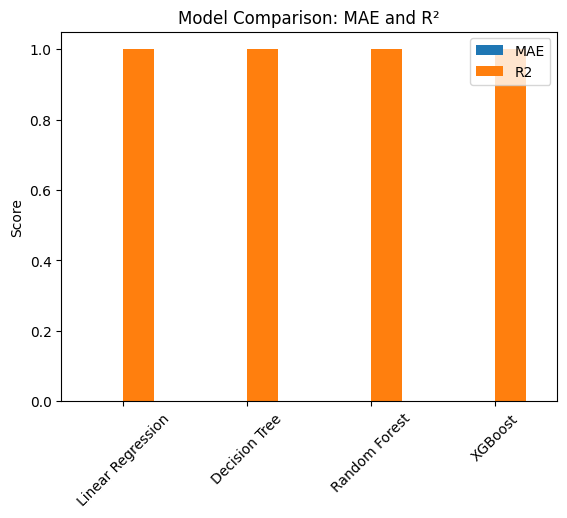

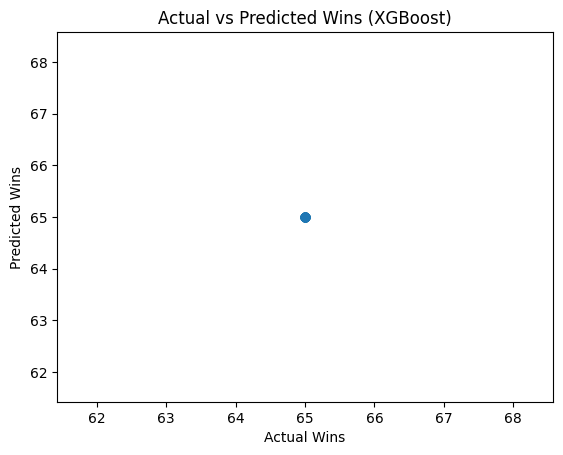


Actual vs Predicted Sample:
   Actual Wins  Predicted Wins
0         65.0            65.0
1         65.0            65.0
2         65.0            65.0
3         65.0            65.0
4         65.0            65.0
5         65.0            65.0
6         65.0            65.0
7         65.0            65.0
8         65.0            65.0
9         65.0            65.0

Feature Importance:
            Feature  Importance
0  Offensive_Rating         0.0
1  Defensive_Rating         0.0
2          Rebounds         0.0
3         Turnovers         0.0
4               eFG         0.0
5       Assist_Rate         0.0
6            Steals         0.0
7            Blocks         0.0
8              Pace         0.0
9    FreeThrow_Rate         0.0


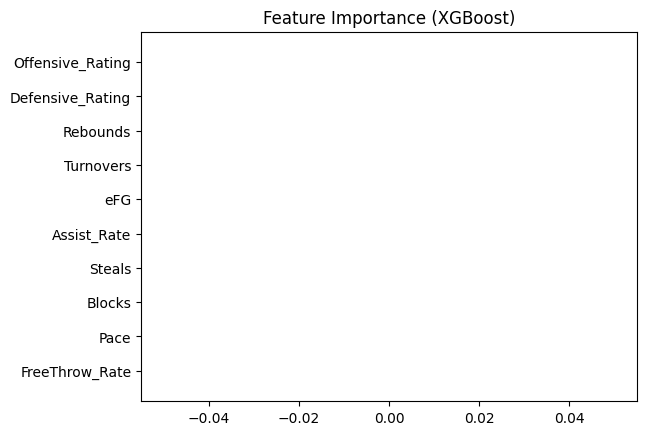


Generating SHAP Feature Importance Plot...


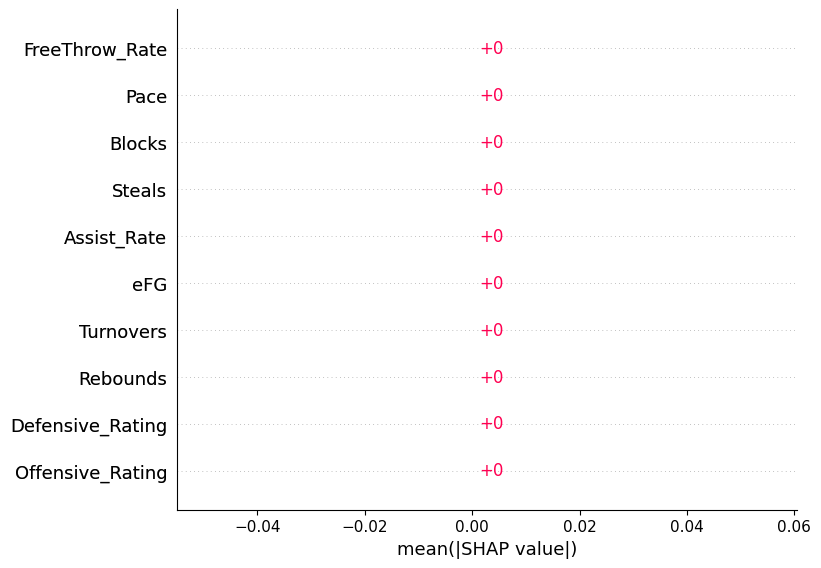

In [ ]:
# NBA Season Wins Prediction Project
# This program compares multiple machine learning models
# to predict total NBA season wins.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import shap


# -------------------------------
# Step 1: Load the Dataset
# -------------------------------

# Read the NBA team-season dataset (make sure the CSV is in the same folder)
data = pd.read_csv("nba_team_data.csv")

# Display the first few rows so we can see what the data looks like
print("First 5 rows of dataset:")
print(data.head())

# Print dataset size (rows and columns)
print("\nDataset shape:", data.shape)


# -------------------------------
# Step 2: Define Features and Target
# -------------------------------

# X contains all input features (team performance statistics)
X = data.drop("Wins", axis=1)

# y is the target variable we want to predict (total season wins)
y = data["Wins"]


# -------------------------------
# Step 3: Split Data (80% Train, 20% Test)
# -------------------------------

# We train the models on 80% of the data
# and test their accuracy on the remaining 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# -------------------------------
# Step 4: Create Machine Learning Models
# -------------------------------

# Linear Regression (basic baseline model)
linear = LinearRegression()

# Decision Tree (single tree model)
decision_tree = DecisionTreeRegressor(random_state=42)

# Random Forest (many trees combined)
random_forest = RandomForestRegressor(n_estimators=500, random_state=42)

# XGBoost (boosting model that improves predictions step-by-step)
xgboost = XGBRegressor(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

# Store models in dictionary so we can loop through them easily
models = {
    "Linear Regression": linear,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "XGBoost": xgboost
}

results = {}


# -------------------------------
# Step 5: Train and Evaluate Models
# -------------------------------

# Loop through each model
for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions on test data
    predictions = model.predict(X_test)

    # Calculate error (MAE) and accuracy (R²)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    # Save results
    results[name] = {
        "MAE": round(mae, 2),
        "R2": round(r2, 2)
    }


# -------------------------------
# Step 6: Show Model Comparison Table
# -------------------------------

results_df = pd.DataFrame(results).T

print("\nModel Comparison:")
print(results_df)


# -------------------------------
# Step 7: Bar Chart Comparison
# -------------------------------

# This graph compares MAE and R² for each model
results_df.plot(kind="bar")
plt.title("Model Comparison: MAE and R²")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.show()


# -------------------------------
# Step 8: Actual vs Predicted (XGBoost)
# -------------------------------

# We use XGBoost as the best performing model
best_model = xgboost
predictions = best_model.predict(X_test)

# Scatter plot of real wins vs predicted wins
plt.scatter(y_test, predictions)
plt.xlabel("Actual Wins")
plt.ylabel("Predicted Wins")
plt.title("Actual vs Predicted Wins (XGBoost)")
plt.show()

# Show sample comparison table
comparison = pd.DataFrame({
    "Actual Wins": y_test.values,
    "Predicted Wins": predictions
})

print("\nActual vs Predicted Sample:")
print(comparison.head(10))


# -------------------------------
# Step 9: Feature Importance (XGBoost)
# -------------------------------

# Get importance scores for each feature
importances = best_model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importance:")
print(importance_df)

# Horizontal bar chart for feature importance
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.title("Feature Importance (XGBoost)")
plt.gca().invert_yaxis()
plt.show()


# -------------------------------
# Step 10: SHAP Analysis
# -------------------------------

# SHAP explains how each feature impacts predictions
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test)

print("\nGenerating SHAP Feature Importance Plot...")
shap.plots.bar(shap_values)